In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = (
    "/kaggle/input/datasets/kimi11/checkpoint/"
    "baseline_resnet18_cifar10.pth"
)

model = models.resnet18(weights=None)
model.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)
model.maxpool = nn.Identity()
model.fc = nn.Linear(model.fc.in_features, 10)

weights = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

if "state_dict" in weights:
    weights = weights["state_dict"]
elif "model_state_dict" in weights:
    weights = weights["model_state_dict"]

weights = {
    k.removeprefix("module."): v
    for k, v in weights.items()
}

model.load_state_dict(weights)
model = model.to(device)
model.eval()

feature_extractor = nn.Sequential(
    *list(model.children())[:-1]
).to(device)

feature_extractor.eval()

print("Model loaded successfully.")
print("Feature extractor created.")

Model loaded successfully.
Feature extractor created.


In [3]:
import os
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

data_dir = "/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C"

# Original clean CIFAR-10 test set
clean_dataset = datasets.CIFAR10(
    root="/kaggle/working/cifar10_data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

clean_loader = DataLoader(
    clean_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

# Gaussian noise, severity 1: first 10,000 images
noisy_images = np.load(
    os.path.join(data_dir, "gaussian_noise.npy"),
    mmap_mode="r"
)[:10000]

noisy_labels = np.load(
    os.path.join(data_dir, "labels.npy"),
    mmap_mode="r"
)[:10000]

clean_images_list = []
clean_labels_list = []

for images, labels in clean_loader:
    clean_images_list.append(images)
    clean_labels_list.append(labels)

clean_images = torch.cat(clean_images_list)
clean_labels = torch.cat(clean_labels_list)

print("Clean images:", clean_images.shape)
print("Clean labels:", clean_labels.shape)
print("Noisy images:", noisy_images.shape)
print("Noisy labels:", noisy_labels.shape)

print(
    "Labels match:",
    np.array_equal(clean_labels.numpy(), noisy_labels)
)

100%|██████████| 170M/170M [50:03<00:00, 56.8kB/s] 


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C/gaussian_noise.npy'

In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for name in files:
        if name in ["gaussian_noise.npy", "labels.npy"]:
            print(os.path.join(root, name))

/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C/labels.npy
/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C/gaussian_noise.npy


In [6]:
import os
import numpy as np

data_dir = "/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C"

noisy_images = np.load(
    os.path.join(data_dir, "gaussian_noise.npy"),
    mmap_mode="r"
)[:10000]

noisy_labels = np.load(
    os.path.join(data_dir, "labels.npy"),
    mmap_mode="r"
)[:10000]

print("Clean images:", clean_images.shape)
print("Clean labels:", clean_labels.shape)
print("Noisy images:", noisy_images.shape)
print("Noisy labels:", noisy_labels.shape)
print("Labels match:", np.array_equal(clean_labels.numpy(), noisy_labels))

NameError: name 'clean_images' is not defined

In [7]:
import os
import numpy as np
import torch
from torchvision import datasets, transforms

data_dir = "/kaggle/input/datasets/harshadakhatu/cifar-10-c/CIFAR-10-C"

# Reuse the CIFAR-10 download from Notebook 04
clean_dataset = datasets.CIFAR10(
    root="/kaggle/working/cifar10_data",
    train=False,
    download=False,
    transform=transforms.ToTensor()
)

clean_images = torch.stack([clean_dataset[i][0] for i in range(len(clean_dataset))])
clean_labels = torch.tensor(clean_dataset.targets)

# Read existing Gaussian-noise data
noisy_images = np.load(
    os.path.join(data_dir, "gaussian_noise.npy"),
    mmap_mode="r"
)[:10000]

noisy_labels = np.load(
    os.path.join(data_dir, "labels.npy"),
    mmap_mode="r"
)[:10000]

print("Clean images:", clean_images.shape)
print("Noisy images:", noisy_images.shape)
print("Labels match:", np.array_equal(clean_labels.numpy(), noisy_labels))

Clean images: torch.Size([10000, 3, 32, 32])
Noisy images: (10000, 32, 32, 3)
Labels match: True


In [8]:
import torch
import numpy as np

feature_extractor.eval()

clean_features_list = []
noisy_features_list = []

with torch.no_grad():
    for start in range(0, 10000, 128):
        end = min(start + 128, 10000)

        # Clean images: already NCHW, values in [0, 1]
        clean_batch = clean_images[start:end].to(device)

        # Noisy images: convert NHWC uint8 to NCHW float
        noisy_batch = torch.from_numpy(
            np.array(noisy_images[start:end], copy=True)
        ).permute(0, 3, 1, 2).float() / 255.0

        noisy_batch = noisy_batch.to(device)

        clean_features = feature_extractor(clean_batch)
        noisy_features = feature_extractor(noisy_batch)

        clean_features_list.append(
            clean_features.flatten(1).cpu().numpy()
        )
        noisy_features_list.append(
            noisy_features.flatten(1).cpu().numpy()
        )

clean_features = np.concatenate(clean_features_list, axis=0)
noisy_features = np.concatenate(noisy_features_list, axis=0)

print("Clean feature shape:", clean_features.shape)
print("Noisy feature shape:", noisy_features.shape)

Clean feature shape: (10000, 512)
Noisy feature shape: (10000, 512)


## Notebook 04 — Step 4: Calculate feature displacement

Now that we have extracted 512-dimensional features for each image, we’ll measure how much each image’s internal representation changes under Gaussian noise.

We’ll use Euclidean distance between the clean and corrupted feature vectors for each corresponding image.

### What this measures

- Small distance: the feature representation changed relatively little.
- Large distance: the representation changed more under Gaussian noise.

A large distance does not automatically mean the prediction is wrong. We’ll test that relationship next.


In [9]:
import numpy as np

# Euclidean distance between corresponding feature vectors
feature_distances = np.linalg.norm(
    clean_features - noisy_features,
    axis=1
)

print("Images compared:", len(feature_distances))
print(f"Mean feature distance: {feature_distances.mean():.4f}")
print(f"Median feature distance: {np.median(feature_distances):.4f}")
print(f"Minimum feature distance: {feature_distances.min():.4f}")
print(f"Maximum feature distance: {feature_distances.max():.4f}")
print(f"Standard deviation: {feature_distances.std():.4f}")

Images compared: 10000
Mean feature distance: 6.3097
Median feature distance: 5.9287
Minimum feature distance: 0.9804
Maximum feature distance: 21.4887
Standard deviation: 2.5412


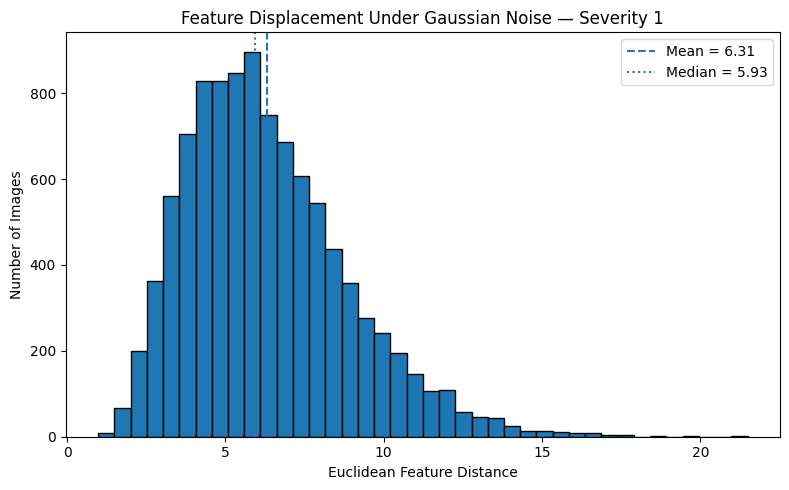

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

plt.hist(feature_distances, bins=40, edgecolor="black")
plt.axvline(
    feature_distances.mean(),
    linestyle="--",
    label=f"Mean = {feature_distances.mean():.2f}"
)
plt.axvline(
    np.median(feature_distances),
    linestyle=":",
    label=f"Median = {np.median(feature_distances):.2f}"
)

plt.xlabel("Euclidean Feature Distance")
plt.ylabel("Number of Images")
plt.title("Feature Displacement Under Gaussian Noise — Severity 1")
plt.legend()
plt.tight_layout()
plt.savefig("fdcc_feature_distance_distribution.png", dpi=300)
plt.show()

In [11]:

import torch
import numpy as np
from scipy.stats import spearmanr

model.eval()

noisy_predictions = []
noisy_confidences = []

with torch.no_grad():
    for start in range(0, 10000, 128):
        end = min(start + 128, 10000)

        batch = torch.from_numpy(
            np.array(noisy_images[start:end], copy=True)
        ).permute(0, 3, 1, 2).float() / 255.0

        batch = batch.to(device)
        logits = model(batch)
        probabilities = torch.softmax(logits, dim=1)

        noisy_predictions.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )
        noisy_confidences.extend(
            probabilities.max(dim=1).values.cpu().numpy()
        )

noisy_predictions = np.array(noisy_predictions)
noisy_confidences = np.array(noisy_confidences)
noisy_correct = noisy_predictions == noisy_labels

correct_distances = feature_distances[noisy_correct]
incorrect_distances = feature_distances[~noisy_correct]

print("Correct predictions:", noisy_correct.sum())
print("Incorrect predictions:", (~noisy_correct).sum())
print(f"Mean distance — correct: {correct_distances.mean():.4f}")
print(f"Mean distance — incorrect: {incorrect_distances.mean():.4f}")

correlation, p_value = spearmanr(
    feature_distances,
    noisy_correct.astype(int)
)

print(f"Spearman correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6g}")


Correct predictions: 7181
Incorrect predictions: 2819
Mean distance — correct: 6.1500
Mean distance — incorrect: 6.7166
Spearman correlation: -0.1003
P-value: 8.53278e-24


Your results show a statistically significant relationship between feature displacement and classification errors under Gaussian noise.The correlation is negative but weak: larger feature distances tend to be associated with incorrect predictions, but feature distance alone is not a strong indicator of whether an individual prediction is wrong. The very small p-value suggests this association is unlikely to be due to random sampling variation under the test's assumptions.

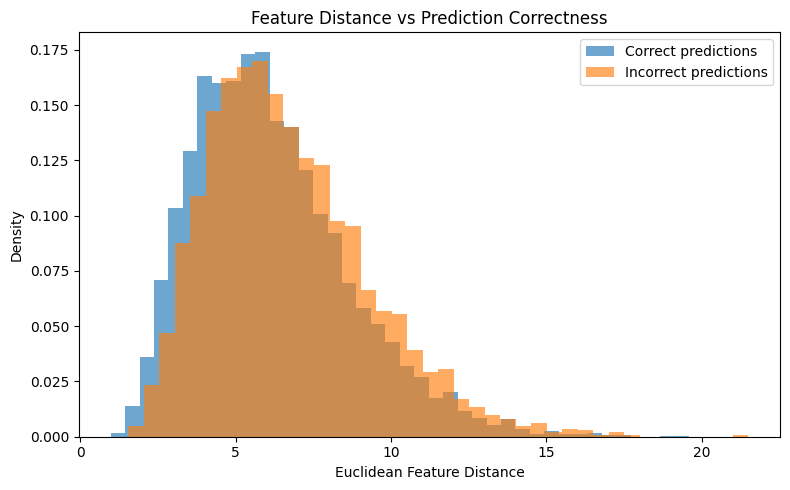

In [12]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

plt.hist(
    correct_distances,
    bins=40,
    alpha=0.65,
    label="Correct predictions",
    density=True
)

plt.hist(
    incorrect_distances,
    bins=40,
    alpha=0.65,
    label="Incorrect predictions",
    density=True
)

plt.xlabel("Euclidean Feature Distance")
plt.ylabel("Density")
plt.title("Feature Distance vs Prediction Correctness")
plt.legend()
plt.tight_layout()
plt.savefig("fdcc_distance_correct_vs_incorrect.png", dpi=300)
plt.show()


This plot will show how much the two distributions overlap. That overlap matters: FDCC needs to determine whether feature displacement provides useful information about confidence, not merely whether the averages differ.

We have established that incorrect predictions have a higher average feature distance. Now we’ll test whether the model’s confidence decreases as feature distance increases.

Spearman correlation: -0.1315
P-value: 8.50083e-40


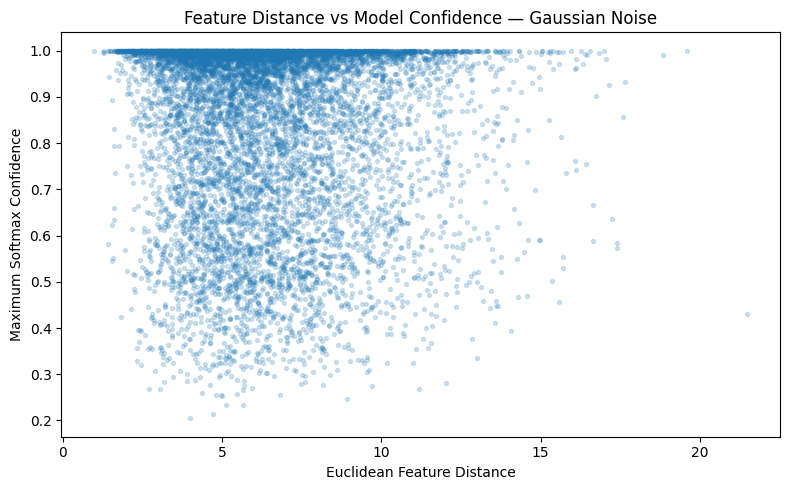

In [13]:

from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import numpy as np

correlation, p_value = spearmanr(
    feature_distances,
    noisy_confidences
)

print(f"Spearman correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6g}")

plt.figure(figsize=(8, 5))
plt.scatter(
    feature_distances,
    noisy_confidences,
    alpha=0.2,
    s=8
)
plt.xlabel("Euclidean Feature Distance")
plt.ylabel("Maximum Softmax Confidence")
plt.title("Feature Distance vs Model Confidence — Gaussian Noise")
plt.tight_layout()
plt.savefig("fdcc_distance_vs_confidence.png", dpi=300)
plt.show()


whether feature displacement is associated with the model's confidence. A negative correlation would mean confidence tends to decrease as feature distance increases; a positive correlation would mean the opposite.
P-value: 8.50083e-40v
The result shows a weak negative association between feature distance and model confidence under Gaussian noise.

Spearman correlation: −0.1315

As feature displacement increases, confidence tends to decrease slightly. However, the relationship is weak, so feature distance alone may not adequately estimate confidence.

In [14]:

import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Mean feature distance",
        "Median feature distance",
        "Feature distance SD",
        "Mean distance — correct predictions",
        "Mean distance — incorrect predictions",
        "Accuracy under Gaussian noise (%)",
        "Distance vs correctness Spearman correlation",
        "Distance vs correctness p-value",
        "Distance vs confidence Spearman correlation",
        "Distance vs confidence p-value"
    ],
    "Value": [
        feature_distances.mean(),
        np.median(feature_distances),
        feature_distances.std(),
        correct_distances.mean(),
        incorrect_distances.mean(),
        noisy_correct.mean() * 100,
        -0.1003,
        8.53278e-24,
        -0.1315,
        8.50083e-40
    ]
})

results.to_csv(
    "fdcc_feature_distance_results.csv",
    index=False
)

results


,Metric,Value
0,Mean feature distance,6.309738e+00
1,Median feature distance,5.928675e+00
2,Feature distance SD,2.541219e+00
3,Mean distance — correct predictions,6.150000e+00
4,Mean distance — incorrect predictions,6.716646e+00
5,Accuracy under Gaussian noise (%),7.181000e+01
6,Distance vs correctness Spearman correlation,-1.003000e-01
7,Distance vs correctness p-value,8.532780e-24
8,Distance vs confidence Spearman correlation,-1.315000e-01
9,Distance vs confidence p-value,8.500830e-40


Step 1: Measure confidence and accuracy across feature-distance groups
We’ll divide the 10,000 Gaussian-noise images into five groups based on feature distance, then compare each group’s average confidence with its actual accuracy.

In [15]:

import pandas as pd
import numpy as np

distance_df = pd.DataFrame({
    "feature_distance": feature_distances,
    "confidence": noisy_confidences,
    "correct": noisy_correct.astype(int)
})

distance_df["distance_group"] = pd.qcut(
    distance_df["feature_distance"],
    q=5,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
)

group_results = distance_df.groupby(
    "distance_group",
    observed=True
).agg(
    image_count=("correct", "size"),
    mean_feature_distance=("feature_distance", "mean"),
    mean_confidence=("confidence", "mean"),
    accuracy=("correct", "mean")
).reset_index()

group_results["accuracy"] *= 100
group_results["mean_confidence"] *= 100
group_results["confidence_minus_accuracy_pp"] = (
    group_results["mean_confidence"] - group_results["accuracy"]
)

group_results.round(3)


,distance_group,image_count,mean_feature_distance,mean_confidence,accuracy,confidence_minus_accuracy_pp
0,Q1 (lowest),2000,3.266,88.222000,79.60,8.622
1,Q2,2000,4.738,84.911003,72.55,12.361
2,Q3,2000,5.946,83.983002,71.30,12.683
3,Q4,2000,7.370,83.867996,69.55,14.318
4,Q5 (highest),2000,10.229,83.794998,66.05,17.745


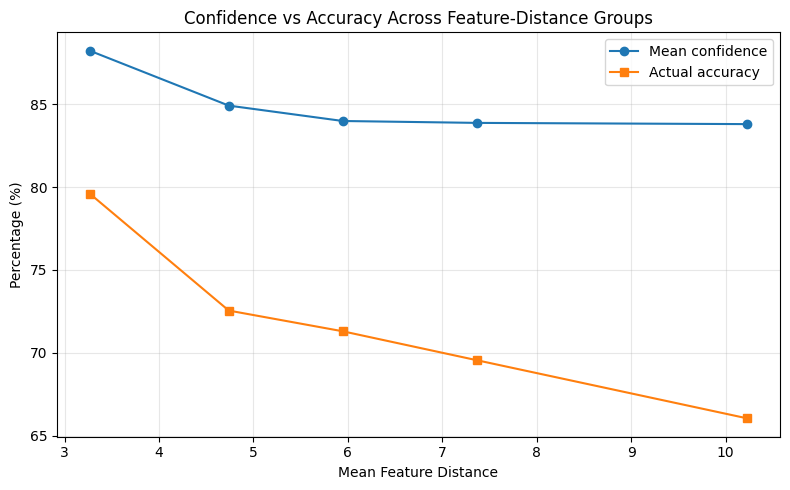

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    group_results["mean_feature_distance"],
    group_results["mean_confidence"],
    marker="o",
    label="Mean confidence"
)

plt.plot(
    group_results["mean_feature_distance"],
    group_results["accuracy"],
    marker="s",
    label="Actual accuracy"
)

plt.xlabel("Mean Feature Distance")
plt.ylabel("Percentage (%)")
plt.title("Confidence vs Accuracy Across Feature-Distance Groups")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fdcc_distance_group_confidence_accuracy.png", dpi=300)
plt.show()


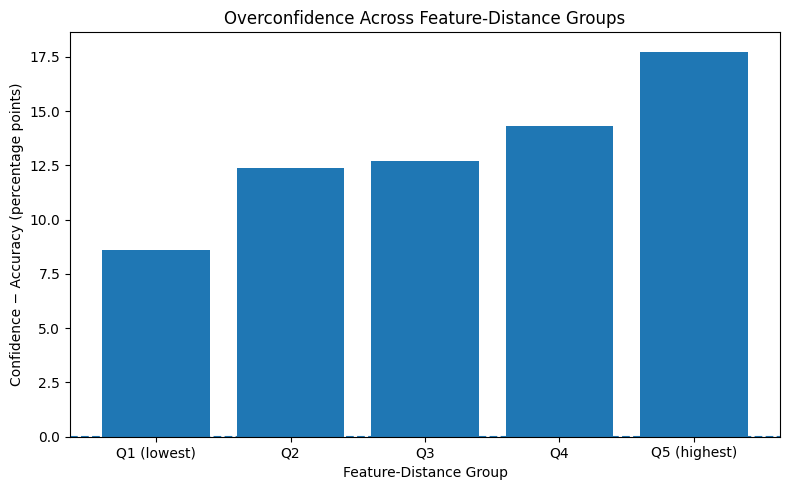

,distance_group,image_count,mean_feature_distance,mean_confidence,accuracy,confidence_minus_accuracy_pp
0,Q1 (lowest),2000,3.266,88.222000,79.60,8.622
1,Q2,2000,4.738,84.911003,72.55,12.361
2,Q3,2000,5.946,83.983002,71.30,12.683
3,Q4,2000,7.370,83.867996,69.55,14.318
4,Q5 (highest),2000,10.229,83.794998,66.05,17.745


In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    group_results["distance_group"].astype(str),
    group_results["confidence_minus_accuracy_pp"]
)

plt.axhline(0, linestyle="--")
plt.xlabel("Feature-Distance Group")
plt.ylabel("Confidence − Accuracy (percentage points)")
plt.title("Overconfidence Across Feature-Distance Groups")
plt.tight_layout()
plt.savefig("fdcc_overconfidence_by_distance_group.png", dpi=300)
plt.show()

display(
    group_results[
        [
            "distance_group",
            "image_count",
            "mean_feature_distance",
            "mean_confidence",
            "accuracy",
            "confidence_minus_accuracy_pp"
        ]
    ].round(3)
)


Interpretation: positive bars indicate group-level overconfidence; negative bars indicate underconfidence. If the gap grows across Q1–Q5, greater feature displacement may be associated with greater overconfidence.

In [18]:

import numpy as np
import pandas as pd

def calculate_ece(confidences, correct, n_bins=15):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidences >= bin_edges[i]) & (
                confidences <= bin_edges[i + 1]
            )
        else:
            mask = (confidences >= bin_edges[i]) & (
                confidences < bin_edges[i + 1]
            )

        if mask.any():
            bin_accuracy = correct[mask].mean()
            bin_confidence = confidences[mask].mean()
            ece += mask.mean() * abs(
                bin_accuracy - bin_confidence
            )

    return ece

ece_results = []

for group in group_results["distance_group"]:
    mask = distance_df["distance_group"] == group

    group_confidence = distance_df.loc[
        mask, "confidence"
    ].to_numpy()

    group_correct = distance_df.loc[
        mask, "correct"
    ].to_numpy()

    ece_results.append({
        "distance_group": str(group),
        "mean_feature_distance": distance_df.loc[
            mask, "feature_distance"
        ].mean(),
        "accuracy_percent": group_correct.mean() * 100,
        "confidence_percent": group_confidence.mean() * 100,
        "ECE": calculate_ece(group_confidence, group_correct)
    })

ece_df = pd.DataFrame(ece_results)
display(ece_df.round(4))


,distance_group,mean_feature_distance,accuracy_percent,confidence_percent,ECE
0,Q1 (lowest),3.2660,79.60,88.221497,0.0870
1,Q2,4.7382,72.55,84.910797,0.1242
2,Q3,5.9459,71.30,83.982903,0.1293
3,Q4,7.3700,69.55,83.868401,0.1440
4,Q5 (highest),10.2286,66.05,83.795097,0.1775


In [19]:

ece_df.to_csv(
    "fdcc_ece_by_feature_distance.csv",
    index=False
)

print("Saved: fdcc_ece_by_feature_distance.csv")


Saved: fdcc_ece_by_feature_distance.csv


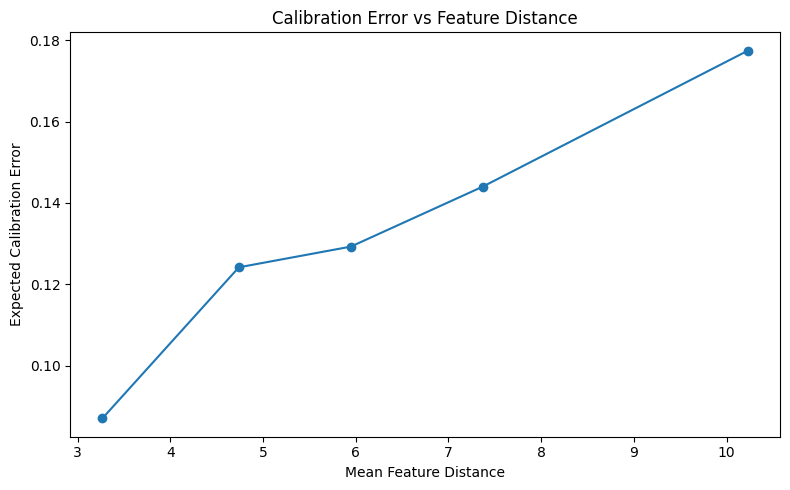

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    ece_df["mean_feature_distance"],
    ece_df["ECE"],
    marker="o"
)
plt.xlabel("Mean Feature Distance")
plt.ylabel("Expected Calibration Error")
plt.title("Calibration Error vs Feature Distance")
plt.tight_layout()
plt.savefig("fdcc_ece_vs_feature_distance.png", dpi=300)
plt.show()


In [21]:

np.savez(
    "gaussian_noise_severity1_predictions.npz",
    predictions=noisy_predictions,
    confidences=noisy_confidences,
    correct=noisy_correct,
    labels=noisy_labels,
    feature_distances=feature_distances
)

print("Saved gaussian_noise_severity1_predictions.npz")


Saved gaussian_noise_severity1_predictions.npz
